In [22]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, roc_auc_score)

In [6]:
dataset = pd.read_csv("DATASET_LIMPIO_ANEMIA.csv")

In [7]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99472 entries, 0 to 99471
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   anemia_materna_embarazo  99472 non-null  int64  
 1   desparasitacion          99472 non-null  int64  
 2   diarrea_reciente         99472 non-null  int64  
 3   fiebre_reciente          99472 non-null  int64  
 4   ANEMIA                   99472 non-null  int64  
 5   edad_meses               99472 non-null  int64  
 6   peso_nino_kg             99472 non-null  float64
 7   talla_nino_cm            99472 non-null  float64
 8   z_talla_edad             99472 non-null  float64
 9   z_peso_edad              99472 non-null  float64
 10  z_peso_talla             99472 non-null  float64
 11  z_imc_edad               99472 non-null  float64
 12  anio_encuesta            99472 non-null  int64  
 13  edad_madre               99472 non-null  int64  
 14  nivel_educativo_madre 

In [9]:
#dividir las variables segun su tipo:
variables_numericas = ['edad_meses', 'peso_nino_kg', 'talla_nino_cm', 'z_talla_edad', 'z_peso_edad',
                       'z_peso_talla', 'z_imc_edad', 'edad_madre', 'anios_educacion_madre', 'altitud_residencia_m',
                       'peso_madre_kg', 'peso_nacer_kg', 'talla_madre_m']
variables_categoricas = ['anemia_materna_embarazo', 'desparasitacion', 'diarrea_reciente', 'fiebre_reciente',
                         'nivel_educativo_madre', 'quintil_riqueza', 'area_residencia', 'sexo_nino',
                         'anemia_materna_actual', 'nivel_pobreza','anio_encuesta','departamento']

In [21]:
#definir las variables predictoras y la variable objetivo:
X = dataset.drop(columns=['ANEMIA'])
y = dataset['ANEMIA']

# Comprobar que todas las columnas estén clasificadas
assert set(variables_numericas + variables_categoricas) == set(X.columns)

#dividir los datos (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#Preprocesamiento de los datos:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), variables_numericas), #Estandarización de variables numéricas
        ('cat', OneHotEncoder(handle_unknown='ignore'), #Conversion de variables categoricas en columnas binarias
         variables_categoricas)
    ]
)

#Definición de los modelos:
#Modelo 1: Sin balancear los datos (0: 60 mil, 1: 30 mil)
pipeline_lr = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

#Modelo 2: Con pesos balanceados
pipeline_lr_balanced = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced', #
        max_iter=2000,
        random_state=42
    ))
])


#Entrenamiento de ambos modelos
pipeline_lr.fit(X_train, y_train) #No balanceado
pipeline_lr_balanced.fit(X_train, y_train) #Balanceado


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['edad_meses', 'peso_nino_kg',
                                                   'talla_nino_cm',
                                                   'z_talla_edad',
                                                   'z_peso_edad',
                                                   'z_peso_talla', 'z_imc_edad',
                                                   'edad_madre',
                                                   'anios_educacion_madre',
                                                   'altitud_residencia_m',
                                                   'peso_madre_kg',
                                                   'peso_nacer_kg',
                                                   'talla_madre_m']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['anemia_materna_embarazo',
                                                   'desparasitacion',
                                                   'diarrea_reciente',
                                                   'fiebre_reciente',
                                                   'nivel_educativo_madre',
                                                   'quintil_riqueza',
                                                   'area_residencia',
                                                   'sexo_nino',
                                                   'anemia_materna_actual',
                                                   'nivel_pobreza',
                                                   'anio_encuesta',
                                                   'departamento'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42))])

In [23]:
#Evaluación de los modelos:
#Modelo sin balancear
y_pred = pipeline_lr.predict(X_test)
y_prob = pipeline_lr.predict_proba(X_test)[:, 1]

print("MODELO SIN BALANCEAR")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

#Modelo con pesos balanceados
y_pred_balanced = pipeline_lr_balanced.predict(X_test)
y_prob_balanced = pipeline_lr_balanced.predict_proba(X_test)[:, 1]

print("\nMODELO CON PESOS BALANCEADOS")
print("Accuracy:", accuracy_score(y_test, y_pred_balanced))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_balanced))
print(classification_report(y_test, y_pred_balanced))
print(confusion_matrix(y_test, y_pred_balanced))


MODELO SIN BALANCEAR
Accuracy: 0.7248052274440814
ROC-AUC: 0.7521520165097975
              precision    recall  f1-score   support

           0       0.75      0.88      0.81     13153
           1       0.64      0.42      0.51      6742

    accuracy                           0.72     19895
   macro avg       0.70      0.65      0.66     19895
weighted avg       0.71      0.72      0.71     19895

[[11601  1552]
 [ 3923  2819]]

MODELO CON PESOS BALANCEADOS
Accuracy: 0.6928373963307364
ROC-AUC: 0.7522373932714361
              precision    recall  f1-score   support

           0       0.81      0.70      0.75     13153
           1       0.54      0.68      0.60      6742

    accuracy                           0.69     19895
   macro avg       0.67      0.69      0.68     19895
weighted avg       0.72      0.69      0.70     19895

[[9219 3934]
 [2177 4565]]


In [24]:
#Graficos de visualización

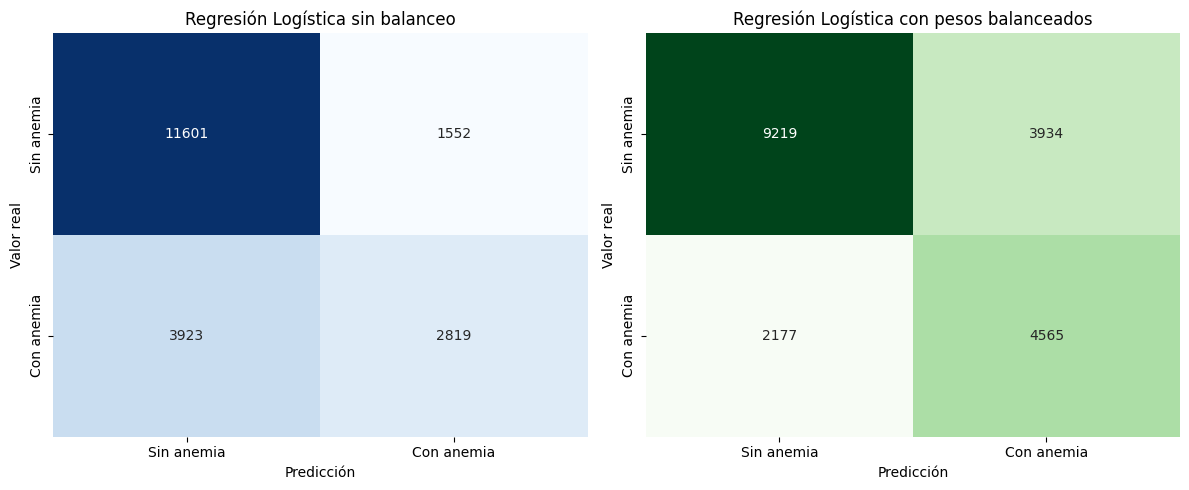

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calcular matrices de confusión
cm_original = confusion_matrix(y_test, y_pred)
cm_balanced = confusion_matrix(y_test, y_pred_balanced)

# Crear gráficos
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    cm_original, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Sin anemia', 'Con anemia'],
    yticklabels=['Sin anemia', 'Con anemia'],
    ax=axes[0], cbar=False
)
axes[0].set_title('Regresión Logística sin balanceo')
axes[0].set_xlabel('Predicción')
axes[0].set_ylabel('Valor real')

sns.heatmap(
    cm_balanced, annot=True, fmt='d', cmap='Greens',
    xticklabels=['Sin anemia', 'Con anemia'],
    yticklabels=['Sin anemia', 'Con anemia'],
    ax=axes[1], cbar=False
)
axes[1].set_title('Regresión Logística con pesos balanceados')
axes[1].set_xlabel('Predicción')
axes[1].set_ylabel('Valor real')

plt.tight_layout()
plt.show()


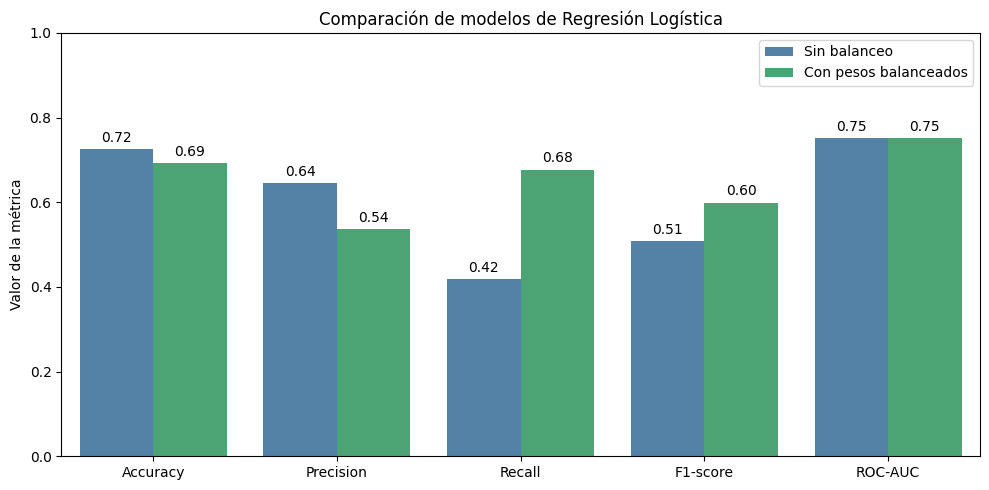

,Métrica,Sin balanceo,Con pesos balanceados
0,Accuracy,0.725,0.693
1,Precision,0.645,0.537
2,Recall,0.418,0.677
3,F1-score,0.507,0.599
4,ROC-AUC,0.752,0.752


In [26]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# Crear tabla comparativa
resultados = pd.DataFrame({
    'Métrica': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'],
    'Sin balanceo': [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ],
    'Con pesos balanceados': [
        accuracy_score(y_test, y_pred_balanced),
        precision_score(y_test, y_pred_balanced),
        recall_score(y_test, y_pred_balanced),
        f1_score(y_test, y_pred_balanced),
        roc_auc_score(y_test, y_prob_balanced)
    ]
})

# Convertir a formato largo
resultados_grafico = resultados.melt(
    id_vars='Métrica',
    var_name='Modelo',
    value_name='Valor'
)

# Crear gráfico
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=resultados_grafico,
    x='Métrica',
    y='Valor',
    hue='Modelo',
    palette=['steelblue', 'mediumseagreen']
)

# Mostrar valores encima de las barras
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.title('Comparación de modelos de Regresión Logística')
plt.ylabel('Valor de la métrica')
plt.xlabel('')
plt.ylim(0, 1)
plt.legend(title='')
plt.tight_layout()
plt.show()

# Mostrar tabla
display(resultados.round(3))